In [34]:
import numpy as np
import matplotlib.pyplot as plt 
import math as mt

In [35]:
psi_x = np.linspace(0,10,1000)
a = psi_x[1]
H = np.zeros((len(psi_x),len(psi_x)))
H[0,0],H[0,1] = 1/a**2, -1/(2*a**2)
H[999,999],H[999,998] =  1/a**2, -1/(2*a**2)

count_j = 1
for i in range(1,999):
    H[i,count_j-1], H[i,count_j],H[i,count_j+1] = -1/(2*a**2), 1/a**2, -1/(2*a**2)
    count_j = count_j+1


In [36]:
lambda_e, lamda_f = np.linalg.eigh(H)

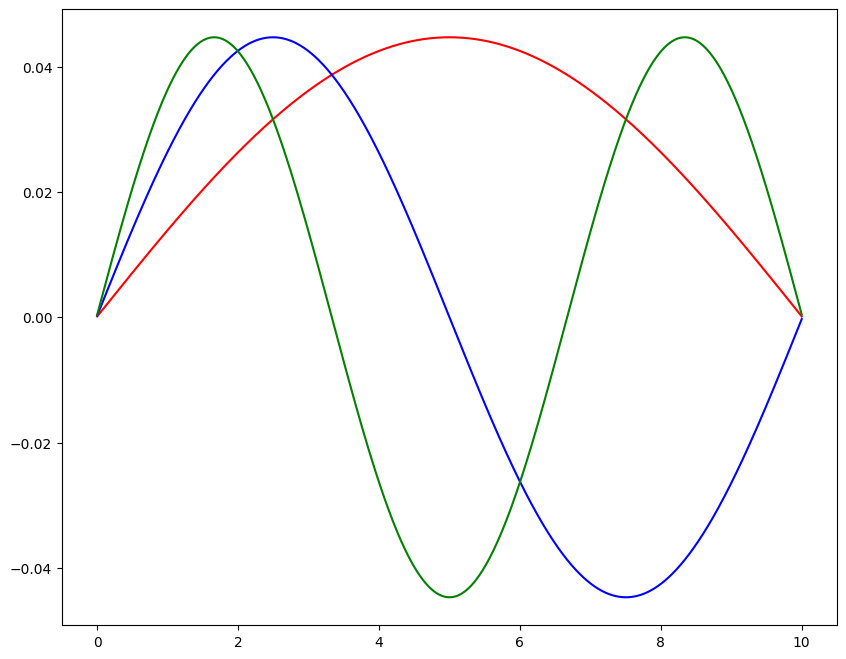

In [37]:
plt.figure(figsize=(10,8))
plt.plot(psi_x,-lamda_f[:,0],'r')
plt.plot(psi_x,-lamda_f[:,1],'b')
plt.plot(psi_x,-lamda_f[:,2],'g')

plt.show()


## Harmonic Oscillator


In [38]:
def H_oscillator(lim,pts):
    psi_x = np.linspace(-lim,lim,pts)
    a = psi_x[1]-psi_x[0]
    H = np.zeros((len(psi_x),len(psi_x)))
    H[0,0],H[0,1] = 1/a**2+ psi_x[0]**2, -1/(2*a**2) 
    H[pts-1,pts-1],H[pts-1,pts-2] =  1/a**2+ psi_x[pts-1]**2, -1/(2*a**2)

    count_j = 1
    for i in range(1,pts-1):
        H[i,count_j-1], H[i,count_j],H[i,count_j+1] = -1/(2*a**2), 1/a**2 + psi_x[i]**2, -1/(2*a**2)
        count_j = count_j+1
    return H

def Kinetic_operator(lim,pts):
    psi_x = np.linspace(-lim,lim,pts)
    a = psi_x[1]-psi_x[0]
    KE = np.zeros((len(psi_x),len(psi_x)))
    KE[0,0],KE[0,1] = 1/a**2, -1/(2*a**2) 
    KE[pts-1,pts-1],KE[pts-1,pts-2] =  1/a**2, -1/(2*a**2)

    count_j = 1
    for i in range(1,pts-1):
        KE[i,count_j-1], KE[i,count_j],KE[i,count_j+1] = -1/(2*a**2), 1/a**2 , -1/(2*a**2)
        count_j = count_j+1
    return KE


In [39]:
lamdaSHO_e, lamdaSHO_f = np.linalg.eigh(H)
print(lamdaSHO_e[0])


0.049150983767153315


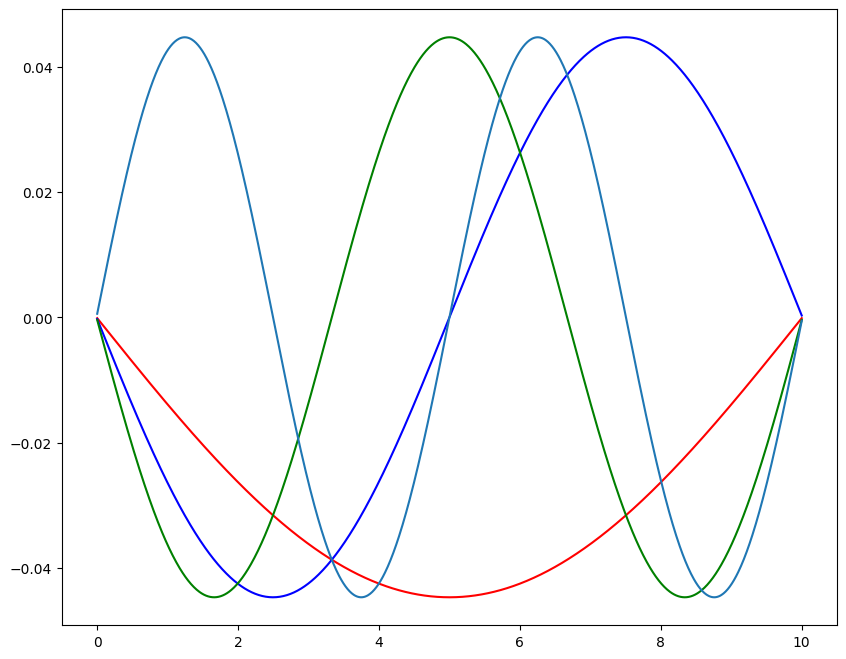

In [40]:
plt.figure(figsize=(10,8))
plt.plot(psi_x,lamdaSHO_f[:,0],'r')
plt.plot(psi_x,lamdaSHO_f[:,1],'b')
plt.plot(psi_x,lamdaSHO_f[:,2],'g')
plt.plot(psi_x,lamdaSHO_f[:,3])



plt.show()


## Density

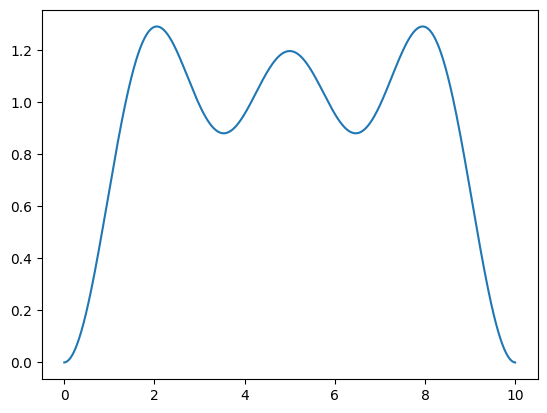

In [41]:
occupation = 3
n_x = (occupation/a)*((abs(lamdaSHO_f[:,0]))**2+(abs(lamdaSHO_f[:,1]))**2+(abs(lamdaSHO_f[:,2]))**2)
plt.plot(psi_x,n_x)
plt.show()


## Exchange Pontetial and Energy

In [42]:
def calculate_exchange(dx,density):
    Ex_potential = -(3/mt.pi)*density**(1/3)
    sum = 0
    for i in range(len(density)):
        sum = sum + dx*(density[i])**4/3
    Ex_Energy = sum*(-3/4)*(3/mt.pi)
    return Ex_potential,Ex_Energy

        


-2.741487684412971


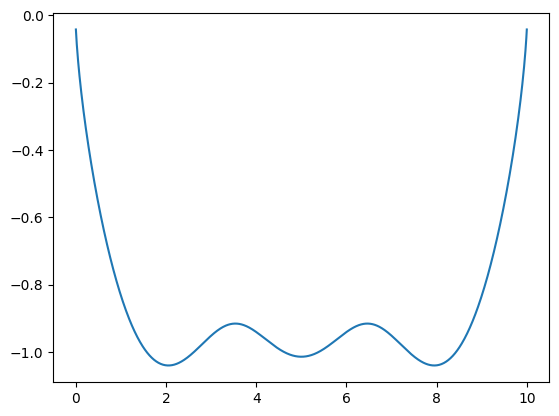

In [43]:
Ex_Potential,Ex_Energy = calculate_exchange(a,n_x)
print(Ex_Energy)
plt.plot(psi_x,Ex_Potential)
plt.show()

## Coloumb Potential and energy

In [44]:
def Calculate_ColoumbE(dx, density,lim, pts):
    
    x_c = np.linspace(-lim,lim, pts)
    dx,dx_p = x_c[1]-x_c[0],x_c[1]-x_c[0]
    nxsum = 0
    for nx,x in zip(density,x_c):
        npsum = 0
        for nx_p,xp in zip(density,x_c):
            npsum = npsum + (nx*nx_p/np.sqrt((x-xp)**2+1))*dx_p
        nxsum = nxsum+ npsum*dx
    ColumbE = 0.5*nxsum
    Coloumb_P = []
    for x in x_c:
        npsum = 0
        for nx_p,xp in zip(density,x_c):
            npsum = npsum + (nx_p/np.sqrt((x-xp)**2+1))*dx_p
        Coloumb_P.append(npsum)
    return Coloumb_P,ColumbE

        


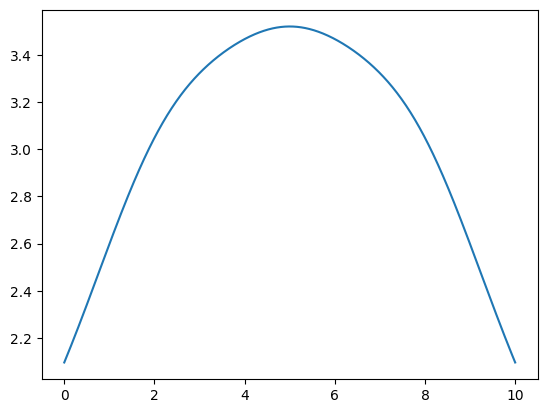

In [55]:
ColoumbP, ColoumbE = Calculate_ColoumbE(a,n_x,3,1000)
plt.plot(psi_x,ColoumbP)
plt.show()

## Self Consistency Loop

In [53]:
def SCF_loop(lim,points,occup,NOE):
    a = np.linspace(-lim,lim,points)
    H_o = Kinetic_operator(lim,points)
    v_ext = 0.5 * a**2
    dx = a[1]-a[0]
    iD = np.zeros(a.shape[0])
    num_states_to_fill = mt.ceil(NOE / occup)
    n_x = iD
    Convergence = 1
    Dens_tresh = 1e-12
    while(Convergence>Dens_tresh):
        Ex_pot1D, Ex_energy = calculate_exchange(dx,n_x)
        Clmb_pot1D, Clmb_energy = Calculate_ColoumbE(dx,n_x,lim,points)
        Vex = np.diag(Ex_pot1D)
        Vcb = np.diag(Clmb_pot1D)
        V_ext = np.diag(v_ext) 
        Comp_Hamil = H_o+Vex+Vcb+V_ext
        H_eig, H_wavfn = np.linalg.eigh(Comp_Hamil)
        new_density = np.zeros(points)
        Orbital_E = 0.0
        prev_n_x = n_x
        for i in range(num_states_to_fill): 
            current_occup = min(occup, NOE - (i * occup))
            psi_squared = np.abs(H_wavfn[:, i])**2
            new_density += (current_occup / dx) * psi_squared 
            Orbital_E += current_occup * H_eig[i]
        n_x = new_density
        total_v_x = Ex_pot1D + Clmb_pot1D + v_ext
        
        pot_integral = np.sum(n_x * total_v_x) * dx
        Kinetic_Energy = Orbital_E - pot_integral
        ext_pot_energy = np.sum(n_x * v_ext) * dx
        Total_Energy = Kinetic_Energy + Clmb_energy + Ex_energy + ext_pot_energy

        print(f"Final Kinetic Energy: {Kinetic_Energy:.6f}")
        print(f"Final Total Energy: {Total_Energy:.6f}")
        Convergence = np.sqrt(np.sum((n_x - prev_n_x)**2) / n_x.shape[0])
        print(Convergence)
SCF_loop(6,500,2,8)
    



Final Kinetic Energy: 8.000000
Final Total Energy: 15.998409
1.0108911179826854
Final Kinetic Energy: 6.436652
Final Total Energy: 27.810980
0.16006723102431852
Final Kinetic Energy: 6.557065
Final Total Energy: 28.966466
0.016506318436263524
Final Kinetic Energy: 6.536760
Final Total Energy: 28.903239
0.002522140512043483
Final Kinetic Energy: 6.539431
Final Total Energy: 28.914785
0.000331342656689715
Final Kinetic Energy: 6.539053
Final Total Energy: 28.913295
4.7259878239636576e-05
Final Kinetic Energy: 6.539105
Final Total Energy: 28.913507
6.4725564130472185e-06
Final Kinetic Energy: 6.539098
Final Total Energy: 28.913478
9.060288968690615e-07
Final Kinetic Energy: 6.539099
Final Total Energy: 28.913482
1.2534206707400065e-07
Final Kinetic Energy: 6.539099
Final Total Energy: 28.913482
1.7453591787939158e-08
Final Kinetic Energy: 6.539099
Final Total Energy: 28.913482
2.4214773095639555e-09
Final Kinetic Energy: 6.539099
Final Total Energy: 28.913482
3.3664810744659e-10
Final Kin

In [49]:
psi_x.shape[0]

1000

In [50]:
np.zeros((1,2))

array([[0., 0.]])